# T19 · Perfis históricos de demanda por bairro

K-Means descritivo nos **94 bairros** dos CSVs processados da Emlurb. Cada ponto é um bairro,
representado por média mensal de chamados observados e total de postes do cadastro de 2025.
Os últimos 12 meses disponíveis são usados como um recorte recente comum, sem usar o alvo futuro.

Grupos de perfis semelhantes não são necessariamente vizinhos. Um grupo com maior volume de chamados
não é uma classificação de segurança, probabilidade de falha ou justificativa automática para aumentar
potência. O score CPTED e a dimerização continuam com seus próprios critérios.

Execute a partir de `applications/ml/notebooks/` com as dependências da central, matplotlib e Jupyter.
Algoritmo e exportação: [`zonas_prioritarias.py`](../src/zonas_prioritarias.py).
Documentação: [K-Means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) e
[silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))
import zonas_prioritarias as Z

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 120})
painel, postes = pd.read_csv(Z.PAINEL), pd.read_csv(Z.POSTES)
bairros, meta = Z.agrupar(painel, postes)
salvos, registro = Z.carregar()
pd.testing.assert_frame_equal(salvos, bairros, check_dtype=False, atol=1e-7, rtol=0)
assert meta["k"] == registro["k"]
print("Período observado:", meta["periodo"])
print("Bairros:", len(bairros), "| k:", meta["k"], "| silhouette:", round(meta["silhouette"], 4))
print("Hashes SHA-256 das fontes:", registro["fontes"])
display(bairros.head())

Período observado: {'inicio': '2024-12', 'fim': '2025-11', 'meses': 12}
Bairros: 94 | k: 3 | silhouette: 0.5332
Hashes SHA-256 das fontes: {'risco_bairro_mes.csv': '36eb7334d936f6822e920e4a68988a587cd0c1ef46184e1c01b78237416d4892', 'postes_por_bairro.csv': '62a2edfe3978295c7f44e57532e4bfc110341c12ebe0646b3a0e1f9d73f4549c'}


,bairro_norm,chamados_total,chamados_media_mensal,total_postes,taxa_1000_postes,zona
0,AFLITOS,122,10.166667,304,33.442982,Z02
1,AFOGADOS,985,82.083333,2382,34.459838,Z01
2,AGUA FRIA,399,33.250000,1874,17.742796,Z01
3,ALTO DO MANDU,0,0.000000,265,0.000000,Z03
4,ALTO JOSE BONIFACIO,197,16.416667,683,24.036115,Z02


## 1. Preparação e escolha de k

Cada bairro precisa ter todos os meses da janela; duplicatas, nulos, valores negativos, infinitos,
contagens fracionárias e cadastro sem correspondência são rejeitados. Ausência de registro não vira zero.
`log1p` reduz a assimetria e `StandardScaler` equilibra as duas unidades antes do K-Means.

Comparamos k de 2 a 6 e escolhemos a maior silhouette, com desempate pelo menor k. Usamos semente 17
e 20 inicializações por candidato. Silhouette mede separação/coerência na **escala transformada**;
não é acurácia nem garante que o número de grupos tenha utilidade operacional.

,k,silhouette,inercia
0,2,0.5226,79.3383
1,3,0.5332,57.4108
2,4,0.4396,42.7947
3,5,0.4504,30.8159
4,6,0.4205,23.4560


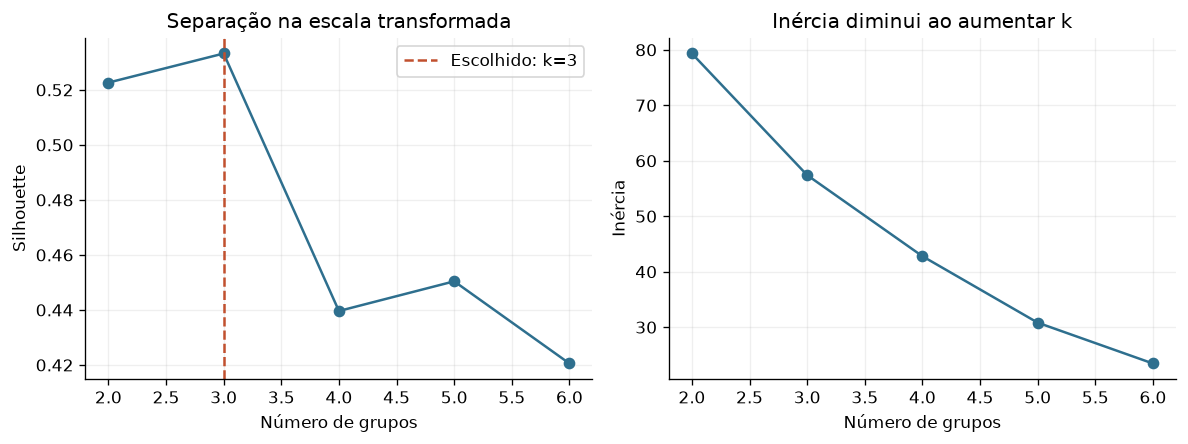

In [2]:
candidatos = pd.DataFrame(meta["candidatos"])
display(candidatos.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(candidatos["k"], candidatos["silhouette"], "o-", color="#2E6F8E")
axes[0].axvline(meta["k"], linestyle="--", color="#C1502E", label=f"Escolhido: k={meta['k']}")
axes[0].set(xlabel="Número de grupos", ylabel="Silhouette", title="Separação na escala transformada")
axes[0].legend()
axes[1].plot(candidatos["k"], candidatos["inercia"], "o-", color="#2E6F8E")
axes[1].set(xlabel="Número de grupos", ylabel="Inércia", title="Inércia diminui ao aumentar k")
plt.tight_layout()
plt.show()

## 2. Grupos por quantidade de postes e chamados

As cores identificam os grupos. Os eixos preservam valores originais com escalas log/symlog para
permitir enxergar bairros de tamanhos diferentes e médias próximas de zero. Losangos representam
os centros do K-Means reconvertidos da escala transformada; não são médias aritméticas dos grupos.
Os IDs são ordenados pela média observada de chamados por bairro, de forma decrescente.

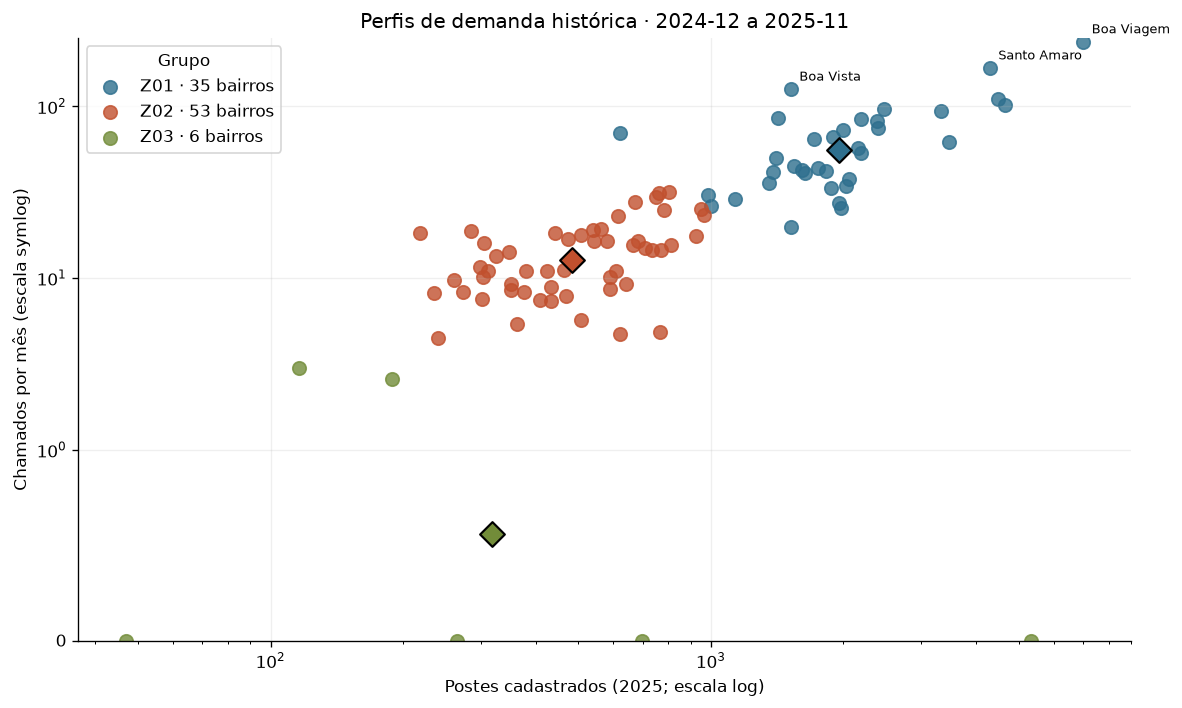

In [3]:
cores = ["#2E6F8E", "#C1502E", "#728C39", "#835BA7", "#D99D28", "#5A7D87"]
fig, ax = plt.subplots(figsize=(10, 6))
for cor, grupo in zip(cores, meta["grupos"]):
    recorte = bairros[bairros["zona"] == grupo["zona"]]
    ax.scatter(recorte["total_postes"], recorte["chamados_media_mensal"], color=cor, s=65,
               alpha=0.8, label=f"{grupo['zona']} · {len(recorte)} bairros")
    ax.scatter(grupo["centro_postes"], grupo["centro_chamados"], marker="D", s=110, color=cor,
               edgecolor="black", linewidth=1.3)
for _, bairro in bairros.nlargest(3, "chamados_media_mensal").iterrows():
    ax.annotate(bairro["bairro_norm"].title(), (bairro["total_postes"], bairro["chamados_media_mensal"]),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(bottom=0)
ax.set(xlabel="Postes cadastrados (2025; escala log)", ylabel="Chamados por mês (escala symlog)",
       title=f"Perfis de demanda histórica · {meta['periodo']['inicio']} a {meta['periodo']['fim']}")
ax.legend(title="Grupo", loc="upper left")
plt.tight_layout()
figuras = Path("../../../docs/figuras/t19")
figuras.mkdir(parents=True, exist_ok=True)
fig.savefig(figuras / "zonas_bairros.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Perfis e taxa por 1.000 postes

A tabela mostra as médias aritméticas dos bairros e os totais por grupo. A taxa do grupo é ponderada
pelo número de postes: soma dos chamados médios mensais / soma dos postes × 1.000. Ela dá contexto,
mas não é uma terceira feature nem determina o agrupamento.

In [4]:
grupos = pd.DataFrame(meta["grupos"])
display(grupos.drop(columns=["centro_chamados", "centro_postes"]).round(3))
display(bairros.sort_values(["zona", "chamados_media_mensal"], ascending=[True, False]).round(3))
print("Estabilidade com quatro sementes adicionais:", meta["estabilidade"])
assert sum(meta_grupo["bairros"] for meta_grupo in meta["grupos"]) == 94
assert bairros["bairro_norm"].nunique() == 94

,zona,bairros,chamados_media_por_bairro,postes_media_por_bairro,chamados_total,postes_total,taxa_1000_postes
0,Z01,35,66.005,2207.771,27722,77272,29.897
1,Z02,53,14.184,523.283,9021,27734,27.106
2,Z03,6,0.931,1109.833,67,6659,0.838


,bairro_norm,chamados_total,chamados_media_mensal,total_postes,taxa_1000_postes,zona
12,BOA VIAGEM,2852,237.667,7013,33.889,Z01
80,SANTO AMARO,2008,167.333,4303,38.888,Z01
13,BOA VISTA,1512,126.000,1520,82.895,Z01
49,IMBIRIBEIRA,1326,110.500,4499,24.561,Z01
91,VARZEA,1217,101.417,4664,21.745,Z01
...,...,...,...,...,...,...
72,PONTO DE PARADA,31,2.583,189,13.668,Z03
3,ALTO DO MANDU,0,0.000,265,0.000,Z03
29,COHAB,0,0.000,5346,0.000,Z03
68,PAU FERRO,0,0.000,47,0.000,Z03


Estabilidade com quatro sementes adicionais: {'sementes': [27, 37, 47, 57], 'ari': [1.0, 0.9334910439288958, 0.9334910439288958, 1.0], 'ari_minimo': 0.9334910439288958}


## 4. Limitações e uso

- O agrupamento reflete registros de chamados e tamanho do parque, não todas as falhas físicas.
  Subnotificação pode produzir poucos chamados mesmo onde há problemas; baixo volume não prova segurança.
- O cadastro de postes é de 2025 e é tratado como estático. A janela é 2024-12–2025-11 porque esse é o
  recorte recente completo disponível no painel processado; não representa o ano civil inteiro de 2025.
- Comparar silhouette de 2 a 6 é uma escolha exploratória limitada, e o K-Means favorece grupos
  compactos na escala adotada. A transformação e a janela influenciam o resultado.
- ARI compara a partição escolhida com quatro sementes adicionais; não é validação temporal nem
  estabilidade garantida sob novos dados. Os IDs de grupos podem mudar ao regenerar os artefatos.
- Os grupos são perfis semelhantes, sem restrição de contiguidade geográfica. Não se deve tratá-los
  como territórios delimitados ou associá-los automaticamente a criminalidade.
- A análise pode apoiar a discussão visual de demanda e segurança do grupo, mas não muda o score AHP,
  o ranking do parque simulado ou a potência dos postes. A API `/zonas` e a aba Zonas apresentam o snapshot.

Para regenerar após mudar os CSVs: `python applications/ml/src/zonas_prioritarias.py` a partir da raiz.
Os hashes das fontes e do CSV exportado detectam artefatos desatualizados ou inconsistentes.